# Random Forest Classifier

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
df = pd.read_csv(r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs\heart_disease.csv")

In [4]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [5]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

## Model Pre- implementation

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state =42)

## Model Implementation

Hyperparameters
There are various hyperparameters that can be controlled in a random forest:

- N_estimators: The number of decision trees being built in the forest. Default values in sklearn are 100. N_estimators are mostly correlated to the size of data, to encapsulate the trends in the data, more number of DTs are needed. 
- Criterion: The function that is used to measure the quality of splits in a decision tree (Classification Problem). Supported criteria are gini: gini impurity or entropy: information gain. In case of Regression Mean Absolute Error (MAE) or Mean Squared Error (MSE) can be used. Default is gini and mse.
- Max_depth: The maximum levels allowed in a decision tree. If set to nothing, The decision tree will keep on splitting until purity is reached.
- Max_features: Maximum number of features used for a node split process. Types: sqrt, log2. If total features are n_features then: sqrt(n_features) or log2(n_features) can be selected as max features for node splitting.
- Bootstrap: Bootstrap samples are used when building decision trees if True is selected in bootstrap, else whole data is used for every decision tree.
- Min_samples_split: This parameter decides the minimum number of samples required to split an internal node. Default value =2. The problem with such a small value is that the condition is checked on the terminal node. If the data points in the node exceed the value 2, then further splitting takes place. Whereas if a more lenient value like 6 is set, then the splitting will stop early and the decision tree wont overfit on the data.
- Min_sample_leaf: This parameter sets the minimum number of data point requirements in a node of the decision tree. It affects the terminal node and basically helps in controlling the depth of the tree. If after a split the data points in a node goes under the min_sample_leaf number, the split won’t go through and will be stopped at the parent node.
- Max_leaf_nodes- With the help of this hyperparameter, a condition can be set on the splitting of the nodes in the tree. Thus, the growth of the tree gets automatically restricted.

In [7]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

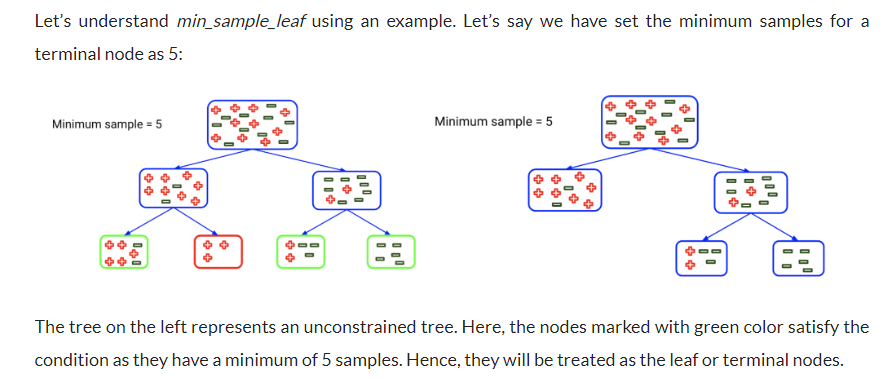

In [3]:
Image.open(os.path.join(dir_path,'RFC_min_sample_leaf.PNG'))

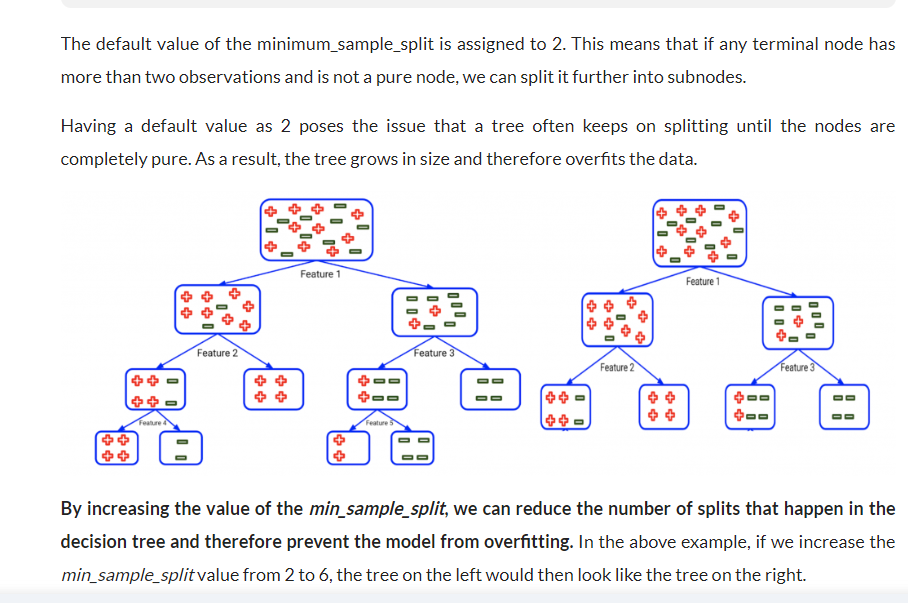

In [4]:
Image.open(os.path.join(dir_path,'RFC_min_sample_split.PNG'))

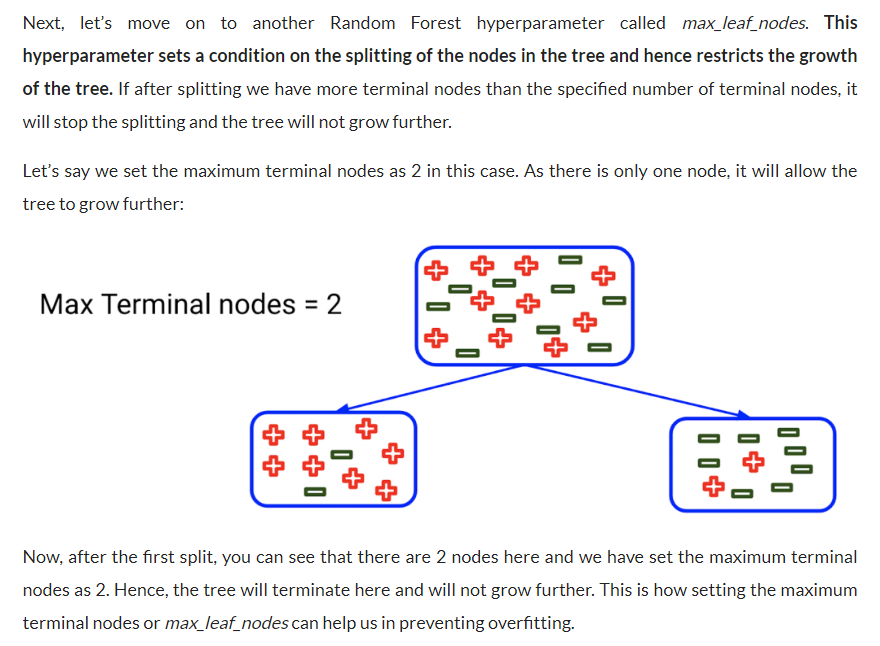

In [5]:
Image.open(os.path.join(dir_path,'RFC_max_leaf_nodes.PNG'))

In [8]:
#---------------------------------------------------------------------------------------------------------------
# Initialize the model --> fit() --> predict()
#---------------------------------------------------------------------------------------------------------------

#---------------------------------------------------------------------------------------------------------------
# Hyperparameters :criterion,max_depth,min_samples_split
#---------------------------------------------------------------------------------------------------------------

rfc = RandomForestClassifier(criterion='gini',max_depth = 8, min_samples_split =8,random_state=42)
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)

## Model Attributes

In [12]:
rfc.feature_importances_                  # rfc.feature_importances_  : importance of all the features
rfc.classes_                              # rfc.classes_ : classes, normally [0,1]
rfc.max_depth

8

<BarContainer object of 13 artists>

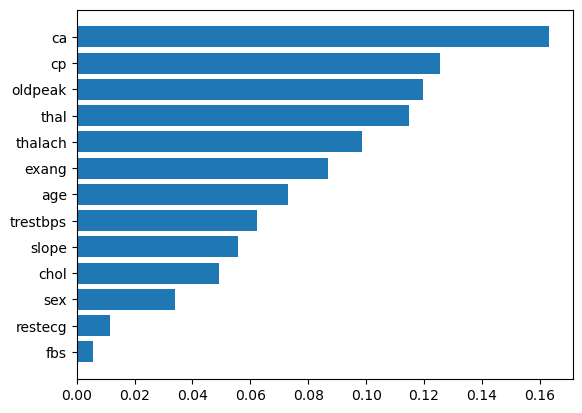

In [43]:
labels = np.array(X.columns)
sorted_index = np.argsort(rfc.feature_importances_)

plt.barh(labels[sorted_index] , width =rfc.feature_importances_[sorted_index])

## Prediction Quality

### Accuracy Score

In [32]:
acc_train = accuracy_score(y_true = y_train,y_pred = rfc.predict(X_train))                           # accuracy_score()
acc_test = accuracy_score(y_true = y_test,y_pred = y_pred)
acc_train, acc_test

(0.9647577092511013, 0.8421052631578947)

### Confusion Matrix

In [26]:
confusion_matrix(y_test, y_pred)           # confusion_matrix()

# ConfusionMatrixDisplay.from_predictor()
disp = ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels = rfc.classes_ , cmap='Blues')    # ConfusionMatrixDisplay.from_predictions
plt.title('Confusion Matrix')
plt.show()

array([[27,  8],
       [ 4, 37]], dtype=int64)

### Classification Report

In [28]:
# Classification Report
print(classification_report(y_test, y_pred))                      # classification_report

              precision    recall  f1-score   support

           0       0.87      0.77      0.82        35
           1       0.82      0.90      0.86        41

    accuracy                           0.84        76
   macro avg       0.85      0.84      0.84        76
weighted avg       0.84      0.84      0.84        76



### Receiver Operator Characterisitc Curve (ROC)

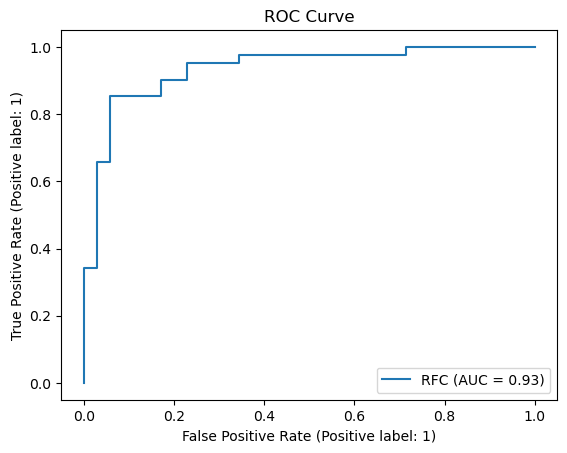

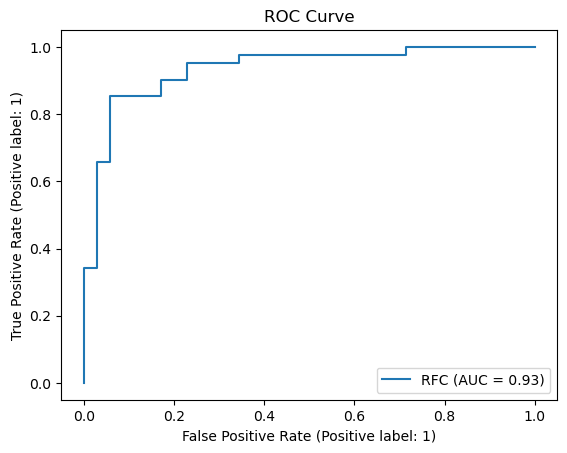

In [37]:
RocCurveDisplay.from_estimator(estimator = rfc, X= X_test, y= y_test, name ='RFC')      # RocCurveDisplay.from_estimator()
plt.title('ROC Curve')
plt.show()

# OR
# The ROC curve uses the decision function. To get the same result, one needs to call decision_function() or predict_proba()

rfc_y_pred_proba = rfc.predict_proba(X_test)                                            # rfc.predict_proba()
rfc_y_pred_proba_positive = rfc_y_pred_proba[:, 1] 
RocCurveDisplay.from_predictions(y_test,rfc_y_pred_proba_positive, name ='RFC')         # RocCurveDisplay.from_predictions()
plt.title('ROC Curve')
plt.show()


In [31]:
roc_curve(y_test,y_pred)

(array([0.        , 0.22857143, 1.        ]),
 array([0.        , 0.90243902, 1.        ]),
 array([2, 1, 0], dtype=int64))